<a href="https://colab.research.google.com/github/rpezoa/mlvalpo/blob/main/proyecto_parametros_estelares.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="border-top:4px solid #1f4e79; border-bottom:1px solid #1f4e79; padding:18px 0 12px 0; margin-bottom:8px;">
<h1 style="text-align:center; font-family:Georgia, serif; margin:0 0 6px 0;">
Proyecto: inferencia de parámetros de estrellas masivas con una red convolucional
</h1>
<p style="text-align:center; font-size:14px; margin:2px 0;">
<b>Escuela de ML Aplicado a Análisis de Estrellas Masivas y eventos de Microlente</b>
</p>
<p style="text-align:center; font-size:13px; margin:4px 0 0 0;">
Sesión <i>Fundamentos de Machine Learning</i>, notebook 3 de 3
</p>
<p style="text-align:center; font-size:13px; margin:4px 0 0 0;">
<b>Raquel Pezoa</b>, Departamento de Informática, Universidad Técnica Federico Santa María
</p>
<p style="text-align:center; font-size:12px; margin:6px 0 0 0; color:#777;">Espectros sintéticos de la grilla ISOSCELES (Araya et al. 2025)</p>
</div>

## Tabla de contenidos

1. [Etapas del proyecto](#sec-1)
2. [Bibliotecas de Python](#sec-2)
3. [Carga de espectros](#sec-3)
4. [Obtención de datos](#sec-4)
5. [Análisis exploratorio de datos (EDA)](#sec-5)
6. [Generación de datos de training, validation y testing](#sec-6)
7. [Diseño e implementación del método de ML](#sec-7)
8. [Validación en el testing set](#sec-8)
9. [Validación en datos observados](#sec-9)
10. [Preguntas abiertas](#sec-10)
11. [Resumen](#sec-11)

---

## Introducción

La estimación de parámetros estelares a partir de espectros es una tarea fundamental en astrofísica. En particular, el análisis de estrellas masivas requiere métodos precisos para estimar parámetros como la temperatura efectiva ($T_\mathrm{eff}$), la velocidad de rotación ($v \sin i$), la gravedad superficial ($\log g$), la luminosidad estelar y la velocidad terminal del viento estelar, entre otros.

En este proyecto se entrena una red neuronal convolucional 1D que predice $T_\mathrm{eff}$, $\log g$ y la tasa de pérdida de masa ($\log \dot M$) a partir de la línea H-alpha, y se evalúa su capacidad de generalizar a espectros observados. A diferencia de los modelos de los notebooks 1 y 2, que tratan cada longitud de onda como una variable independiente, una red convolucional aprovecha que los puntos vecinos de un espectro están relacionados.

**Objetivos de aprendizaje**

- Recorrer las etapas de un proyecto de machine learning, desde la exploración de los datos hasta la validación.
- Escalar variables objetivo de magnitudes muy distintas.
- Diseñar, entrenar y diagnosticar una CNN 1D en Keras.
- Identificar cuándo un modelo extrapola fuera del dominio de entrenamiento.

**Datos.** Subconjunto de la base de datos ISOSCELES ([Araya et al. 2025](https://arxiv.org/abs/2511.03184)) restringido a la línea H-alpha, con velocidad de microturbulencia fija en 10 km/s, y 76 espectros observados.

<a id="sec-1"></a>

---
## 1. Etapas del proyecto

| Etapa | Pregunta que responde |
|---|---|
| 1. Obtención de datos | ¿Qué espectros y qué etiquetas tenemos? |
| 2. EDA | ¿Cómo se distribuyen los parámetros que queremos predecir? |
| 3. Training, validation y testing | ¿Con qué datos entrenamos y con cuáles evaluamos? |
| 4. Diseño del modelo | ¿Qué arquitectura usamos para pasar de un espectro a tres parámetros? |
| 5. Validación en testing | ¿Qué tan bien predice espectros sintéticos que no vio? |
| 6. Validación en datos observados | ¿Generaliza a espectros reales? |

**Sobre ISOSCELES.** ISOSCELES (*grId of Stellar atmOSphere and hydrodynamiC modELs for massivE Stars*) es una grilla de espectros sintéticos de estrellas OBA de metalicidad solar, construida con soluciones hidrodinámicas de viento del código Hydwind y perfiles de línea del código Fastwind ([Araya et al. 2025, arXiv:2511.03184](https://arxiv.org/abs/2511.03184)).

**Sobre H-alpha.** La línea H-alpha (6563 Å) del hidrógeno es sensible al **viento estelar**: cuanto mayor es la pérdida de masa, más se rellena la absorción con emisión. Por eso es una buena línea para estimar $\log \dot M$.

<a id="sec-2"></a>

---
## 2. Bibliotecas de Python

In [1]:
# !pip install tensorflow   # solo si trabaja en local y no tiene TensorFlow
import tensorflow as tf     # se importa primero: en Windows evita conflictos de DLL
import keras
import keras_tuner

import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score

keras.utils.set_random_seed(42)  # resultados reproducibles
print(f"TensorFlow {tf.__version__} | GPU disponible: {bool(tf.config.list_physical_devices('GPU'))}")

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

I0000 00:00:1793936703.725224   41681 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.21.0 | GPU disponible: True


<a id="sec-3"></a>

---
## 3. Carga de espectros

Se descargan tres archivos:

| Archivo | Contenido |
|---|---|
| `subset_vmic10.npy` | 10 000 espectros sintéticos de H-alpha, 200 puntos de flujo cada uno |
| `y_subset_vmic10.npy` | 9 parámetros de cada espectro sintético |
| `X_observed.npy` | 76 espectros observados, 8 líneas por estrella |

> **Nota.** `obtener_archivo` busca primero los archivos en el computador y, si no los encuentra, los descarga desde Google Drive.

In [2]:
def obtener_archivo(nombre, drive_id, carpetas_locales=()):
    """
    Devuelve la ruta local de un archivo de datos.

    Busca `nombre` en la carpeta de la variable de entorno MLVALPO_DATA, luego en
    `carpetas_locales` y en la carpeta actual. Si no lo encuentra, lo descarga
    desde Google Drive.

    Parámetros
    ----------
    nombre           : str   -- nombre del archivo
    drive_id         : str   -- identificador del archivo en Google Drive
    carpetas_locales : lista -- carpetas adicionales donde buscar

    Retorna
    -------
    str -- ruta del archivo
    """
    carpetas = [os.environ.get("MLVALPO_DATA", ""), *carpetas_locales, "."]
    for carpeta in carpetas:
        ruta = os.path.join(carpeta, nombre)
        if carpeta and os.path.exists(ruta):
            print(f"{nombre} encontrado en {carpeta}")
            return ruta
    import gdown  # viene instalado en Colab; en local: pip install gdown
    print(f"Descargando {nombre} desde Google Drive...")
    gdown.download(f"https://drive.google.com/uc?id={drive_id}", nombre, quiet=True)
    return nombre


# Dataset provided by PhD (c) Daniela Turis, IFA-UV.
CARPETA_SINTETICOS = "/Users/rpezoa/experiment_data/data_fo/data_vmic10/"
CARPETA_OBSERVADOS = "/Users/rpezoa/experiment_data/data_fo/data/"

data = np.load(obtener_archivo("subset_vmic10.npy", "14NHeV1fvE2HXMaghHAszf_92iTBVNJHL", [CARPETA_SINTETICOS]))
y = np.load(obtener_archivo("y_subset_vmic10.npy", "1g56JSd46v1HjJkhpIw7Qkal--VDd7cpS", [CARPETA_SINTETICOS]))
data_observed = np.load(obtener_archivo("X_observed.npy", "1YA9HYeOKHMYvt9M4LAaLkO8mpJjOXktV", [CARPETA_OBSERVADOS]))

# Versión preprocesada de H-alpha observada (por ahora solo disponible en local)
ruta_procesados = os.path.join(CARPETA_OBSERVADOS, "X_observed_processed.npy")
data_observed_p = np.load(ruta_procesados) if os.path.exists(ruta_procesados) else None
print("H-alpha observada preprocesada:", "disponible" if data_observed_p is not None else "no disponible (se usará la línea sin procesar)")

subset_vmic10.npy encontrado en .
y_subset_vmic10.npy encontrado en .
X_observed.npy encontrado en .
H-alpha observada preprocesada: no disponible (se usará la línea sin procesar)


<a id="sec-4"></a>

---
## 4. Obtención de datos

`data` contiene los espectros e `y` los parámetros de cada uno.

In [3]:
print("data:", data.shape, "  (espectros, puntos de flujo)")
print("y:   ", y.shape, "  (espectros, parámetros)")

data: (10000, 200)   (espectros, puntos de flujo)
y:    (10000, 9)   (espectros, parámetros)


In [4]:
PARAMETROS = ["TEFF", "LOGG", "LOGLSTAR", "ALPHA", "K", "DELTA", "VINF", "LOGMDOT", "SI"]
DESCRIPCION = [
    "Temperatura efectiva [K]",
    "Logaritmo de la gravedad superficial",
    "Logaritmo de la luminosidad de la estrella",
    "Parámetro de fuerza de línea alpha",
    "Parámetro de fuerza de línea k",
    "Parámetro de fuerza de línea delta",
    "Velocidad terminal del viento [km/s]",
    "Logaritmo de la tasa de pérdida de masa",
    "Abundancia del silicio",
]
resumen = pd.DataFrame({"Descripción": DESCRIPCION, "Mínimo": y.min(axis=0), "Máximo": y.max(axis=0),
                        "Valores distintos": [len(np.unique(c)) for c in y.T]}, index=PARAMETROS)
resumen.style.format({"Mínimo": "{:.2f}", "Máximo": "{:.2f}"})

,Descripción,Mínimo,Máximo,Valores distintos
TEFF,Temperatura efectiva [K],9000.00,45000.00,58
LOGG,Logaritmo de la gravedad superficial,1.65,4.20,18
LOGLSTAR,Logaritmo de la luminosidad de la estrella,2.76,5.65,476
ALPHA,Parámetro de fuerza de línea alpha,0.45,0.57,6
K,Parámetro de fuerza de línea k,0.05,0.60,12
DELTA,Parámetro de fuerza de línea delta,0.29,0.35,7
VINF,Velocidad terminal del viento [km/s],172.49,673.07,7111
LOGMDOT,Logaritmo de la tasa de pérdida de masa,-11.32,-4.99,7111
SI,Abundancia del silicio,7.21,7.81,5


* Solo se deben seleccionar **TEFF**, **LOGG** y **LOGMDOT** (columnas 0, 1 y 7).
* Como ISOSCELES es una **grilla**, algunos parámetros toman pocos valores distintos (por ejemplo, $\log g$ toma 18).

In [5]:
y_new = y[:, [0, 1, 7]]
NOMBRES = ["$T_{eff}$ [K]", "$\\log g$", "$\\log \\dot{M}$"]
COLORES = ["skyblue", "lightgreen", "salmon"]
y_new.shape

(10000, 3)

### 4.1 Ejemplo de un espectro sintético

Las curvas son la línea H-alpha muestreada en 200 puntos. Los espectros sintéticos no incluyen la longitud de onda de cada punto, así que el eje horizontal muestra el **índice del píxel**.

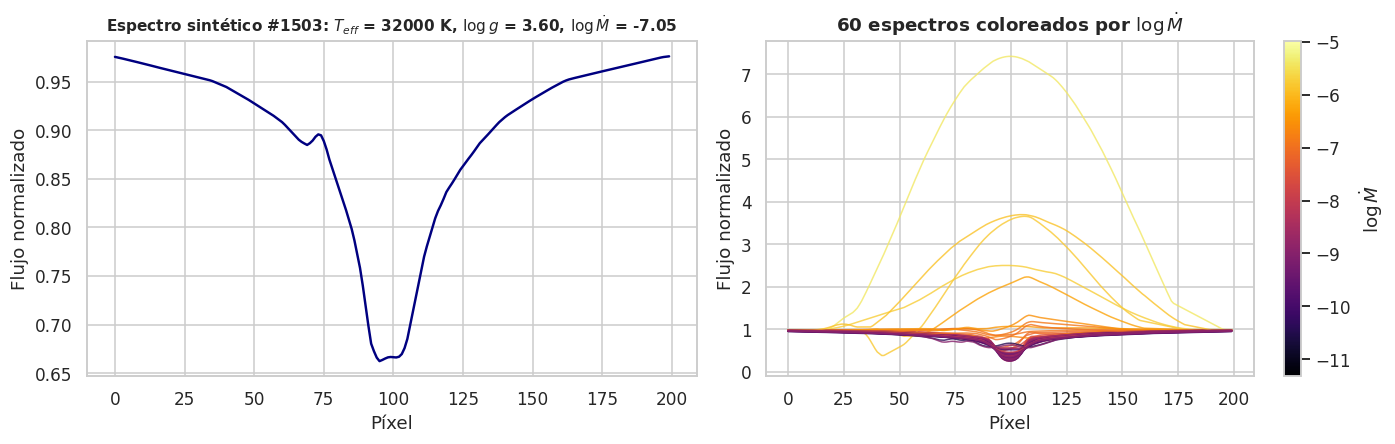

TEFF        32000.000
LOGG            3.600
LOGLSTAR        5.004
ALPHA           0.450
K               0.250
DELTA           0.330
VINF          416.556
LOGMDOT        -7.049
SI              7.360
dtype: float64

In [6]:
i = 1503
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Un espectro
axes[0].plot(range(200), data[i, :], color="navy", lw=1.6)
axes[0].set(title=f"Espectro sintético #{i}: $T_{{eff}}$ = {y[i, 0]:.0f} K, $\\log g$ = {y[i, 1]:.2f}, "
                  f"$\\log \\dot{{M}}$ = {y[i, 7]:.2f}",
            xlabel="Píxel", ylabel="Flujo normalizado")
axes[0].title.set_fontsize(10)

# Varios espectros coloreados por pérdida de masa
rng = np.random.default_rng(0)
idx = rng.choice(len(data), 60, replace=False)
norm = plt.Normalize(y[:, 7].min(), y[:, 7].max())
cmap = plt.cm.inferno
for j in idx:
    axes[1].plot(range(200), data[j, :], color=cmap(norm(y[j, 7])), lw=1, alpha=0.8)
axes[1].set(title="60 espectros coloreados por $\\log \\dot{M}$", xlabel="Píxel", ylabel="Flujo normalizado")
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes[1], label="$\\log \\dot{M}$")

plt.tight_layout()
plt.show()

pd.Series(y[i], index=PARAMETROS).round(3)

<a id="sec-5"></a>

---
## 5. Análisis exploratorio de datos (EDA)

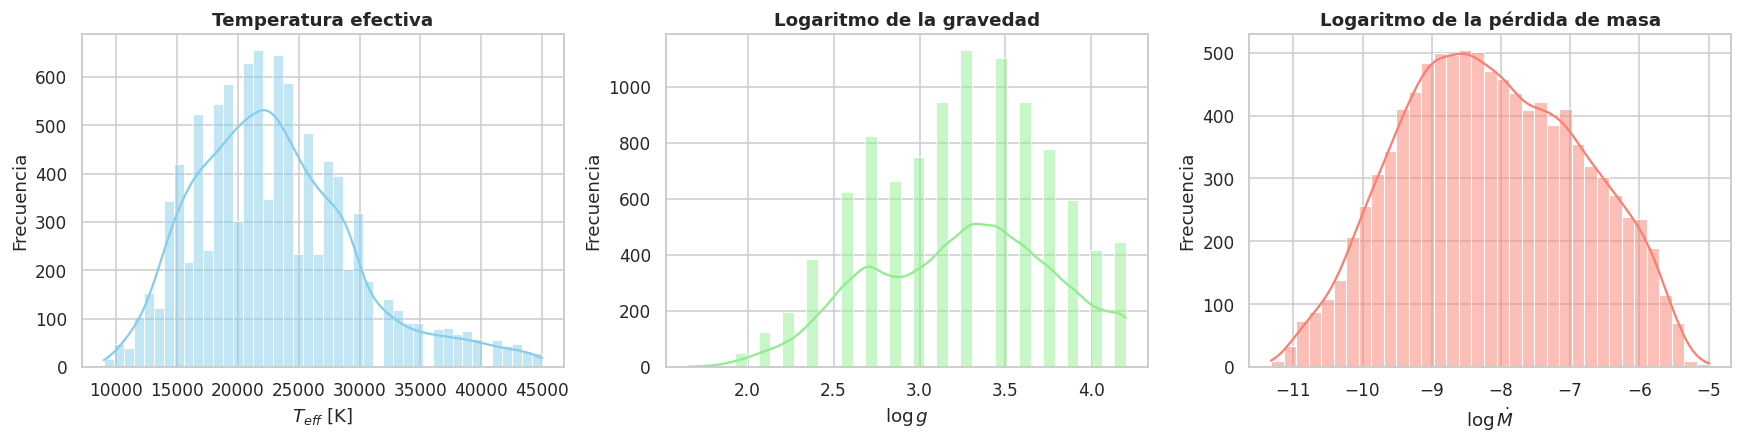

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for k, ax in enumerate(axes):
    sns.histplot(y_new[:, k], kde=True, color=COLORES[k], ax=ax)
    ax.set(title=["Temperatura efectiva", "Logaritmo de la gravedad", "Logaritmo de la pérdida de masa"][k],
           xlabel=NOMBRES[k], ylabel="Frecuencia")
plt.tight_layout()
plt.show()

<a id="sec-6"></a>

---
## 6. Generación de datos de training, validation y testing

### 6.1 Escalamiento de los datos

* Se escalan los valores de salida.
* Los tres parámetros viven en escalas muy distintas ($T_\mathrm{eff} \sim 10^4$ K, $\log g \sim 3$, $\log \dot M \sim -8$). Si no se escalan, la función de pérdida queda dominada por $T_\mathrm{eff}$. `MinMaxScaler` lleva cada parámetro al intervalo $[0, 1]$:

$$
y' = \frac{y - y_{\min}}{y_{\max} - y_{\min}}.
$$

Al final, `scaler.inverse_transform` devuelve las predicciones a sus unidades físicas.

In [8]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(y_new)
y_scaled = scaler.transform(y_new)

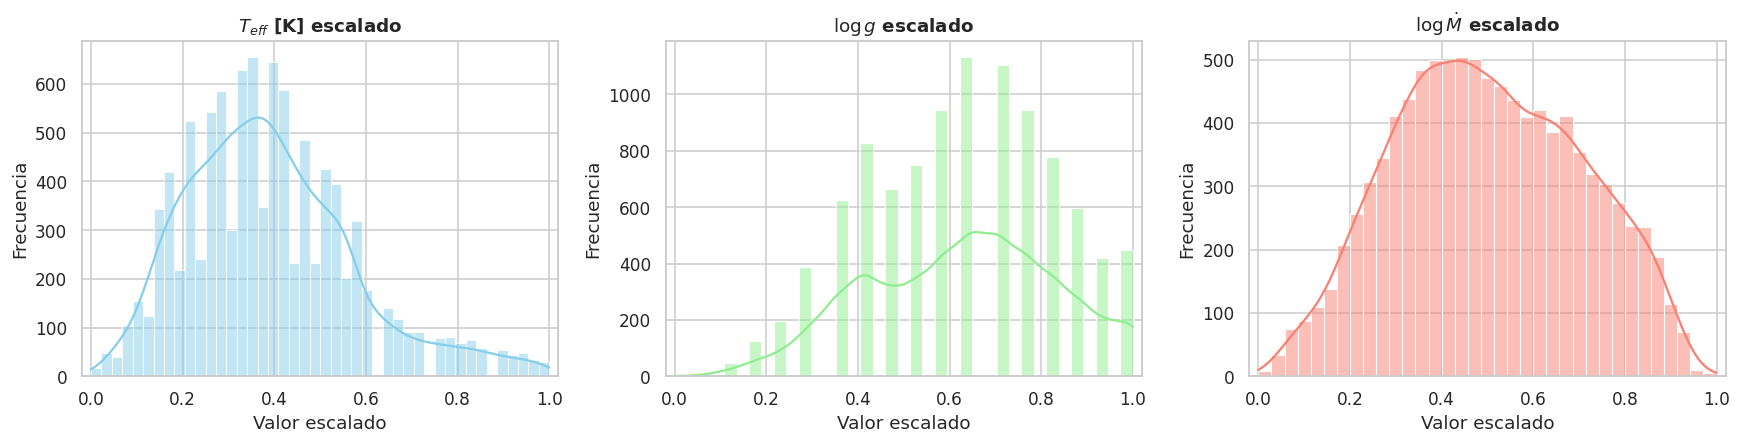

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for k, ax in enumerate(axes):
    sns.histplot(y_scaled[:, k], kde=True, color=COLORES[k], ax=ax)
    ax.set(title=f"{NOMBRES[k]} escalado", xlabel="Valor escalado", ylabel="Frecuencia", xlim=(-0.02, 1.02))
plt.tight_layout()
plt.show()

### 6.2 Partición de los datos

Igual que en los notebooks anteriores: 64 % training, 16 % validation y 20 % testing.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(data, y_scaled, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

<a id="sec-7"></a>

---
## 7. Diseño e implementación del método de ML

### 7.1 Formato de entrada para una CNN 1D

Una capa `Conv1D` de Keras espera datos con forma **(muestras, pasos, canales)**. Cada espectro es una secuencia de 200 pasos con un solo canal (el flujo), así que pasamos de `(n, 200)` a `(n, 200, 1)`.

In [11]:
time_steps = X_train.shape[1]
input_dimension = 1

sample_size = X_train.shape[0]
X_train_reshaped = X_train.reshape((sample_size, time_steps, input_dimension))
sample_size = X_val.shape[0]
X_val_reshaped = X_val.reshape((sample_size, time_steps, input_dimension))
sample_size = X_test.shape[0]
X_test_reshaped = X_test.reshape((sample_size, time_steps, input_dimension))

print("Training:  ", X_train_reshaped.shape)
print("Validation:", X_val_reshaped.shape)
print("Testing:   ", X_test_reshaped.shape)

Training:   (6400, 200, 1)
Validation: (1600, 200, 1)
Testing:    (2000, 200, 1)


# Entrenando el modelo

In [12]:
def build_conv1D_model(hp):
    """Construye y compila la CNN 1D: espectro de 200 píxeles -> [T_eff, log g, log Mdot] escalados."""
    n_timesteps = X_train_reshaped.shape[1]  # 200
    n_features = X_train_reshaped.shape[2]   # 1
    model = keras.Sequential(name="model_conv1D")
    model.add(keras.layers.Input(shape=(n_timesteps, n_features)))
    
    for i in range(hp.Int("num_layers", 2, 4, 1)):    
        model.add(keras.layers.Conv1D(filters=hp.Int(name="filters"+str(i),min_value=16, max_value=128, step=2, sampling="log"),
        kernel_size=hp.Int("kernel"+str(i), 3, 7, step=2),
        activation=hp.Choice("activation"+str(i), ["elu", "relu", "tanh"]), 
        name="Conv1D_"+str(i)))
        if(hp.Boolean("batchNormalization")):
            model.add(keras.layers.BatchNormalization())
        model.add(keras.layers.Dropout(rate=hp.Float("rate"+str(i), 0.0, 0.4,0.1)))
    
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(32, activation="selu", name="Dense_1"))
    model.add(keras.layers.Dense(3, activation="linear", name="Dense_4"))

    
    if hp.Choice("optimizer", ["rms", "adam"]) == "rms": 
        optimizer = optimizer = tf.keras.optimizers.RMSprop(0.001)
    else: optimizer = keras.optimizers.Adam()
    model.compile(loss='mse', optimizer= optimizer, metrics=['mse'])
    return model

tuner = keras_tuner.BayesianOptimization(
    hypermodel=build_conv1D_model,
    objective="val_loss",
    max_trials=20,
    seed=43,
    max_retries_per_trial=1,
    overwrite=True,
    directory="proyect1Models",
    project_name="convTuned",
)

tuner.search(X_train_reshaped, 
             y_train, 
             epochs=50, 
             validation_data=(X_val_reshaped, y_val),
             callbacks=[keras.callbacks.EarlyStopping(patience=7),
             keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=7)])

mejorModelo = tuner.get_best_models(num_models=1)[0]
mejorModelo.save("mejorModeloTuneado.keras")
mejoresParametros = tuner.get_best_hyperparameters()
print(mejoresParametros)

Trial 20 Complete [00h 00m 41s]
val_loss: 0.00421680323779583

Best val_loss So Far: 0.0020280673634260893
Total elapsed time: 00h 08m 39s


/home/evi/anaconda3/envs/machineLearning/lib/python3.10/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


### 7.3 Entrenamiento

* Una **época** es una pasada completa por el conjunto de training.
* `EarlyStopping` detiene el entrenamiento si la pérdida no mejora durante 5 épocas seguidas (`patience=5`).

In [13]:
model_conv1D = mejorModelo
model_conv1D.summary()

Model: "model_conv1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv1D_0 (Conv1D)               │ (None, 198, 32)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 198, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_1 (Conv1D)               │ (None, 196, 32)        │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 196, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 32)             │       200,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_4 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 204,067 (797.14 KB)

 Trainable params: 204,067 (797.14 KB)

 Non-trainable params: 0 (0.00 B)

### 7.4 Curvas de aprendizaje

Si la pérdida de validation baja junto con la de training, el modelo está aprendiendo patrones que generalizan. Si la de training sigue bajando y la de validation sube, hay **sobreajuste**.

Epoch 1/50


I1106 00:53:48.777197   41908 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_664893__.11


320/320 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0043 - mse: 0.0043 - val_loss: 0.0025 - val_mse: 0.0025 - learning_rate: 0.0010
Epoch 2/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0039 - mse: 0.0039 - val_loss: 0.0025 - val_mse: 0.0025 - learning_rate: 0.0010
Epoch 3/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0035 - mse: 0.0035 - val_loss: 0.0023 - val_mse: 0.0023 - learning_rate: 0.0010
Epoch 4/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0035 - mse: 0.0035 - val_loss: 0.0022 - val_mse: 0.0022 - learning_rate: 0.0010
Epoch 5/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0034 - mse: 0.0034 - val_loss: 0.0023 - val_mse: 0.0023 - learning_rate: 0.0010
Epoch 6/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0034 - mse: 0.0034 - val_loss: 0.0023 - val_mse: 0.0023 - learning_rate: 0.0010
Epoch 7/50
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0033 - mse: 0.0033 - val_loss: 0.0025 - val_mse: 0.0025 - learning_rate: 0.0010
Epoch 8/50
320/32

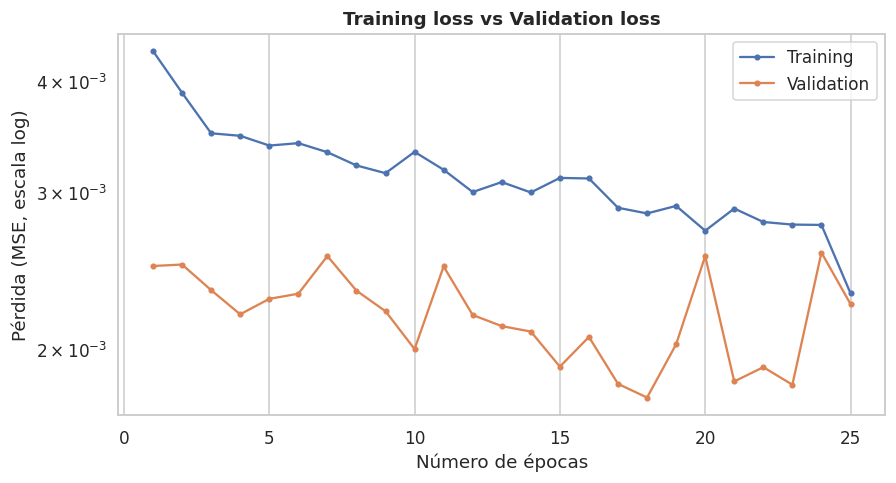

In [14]:
def plot_train_val(A, B, xlabel, ylabel, title):
    """
    Grafica dos curvas por época (training y validation) en escala logarítmica.

    Parámetros
    ----------
    A, B          : listas  -- valores por época de training y de validation
    xlabel, ylabel : str    -- etiquetas de los ejes
    title         : str     -- título del gráfico
    """
    epocas = range(1, len(A) + 1)
    plt.figure(figsize=(9, 4.5))
    plt.plot(epocas, A, "o-", ms=3, label="Training")
    plt.plot(epocas, B, "o-", ms=3, label="Validation")
    plt.yscale("log")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()
    plt.show()

history = mejorModelo.fit(X_train_reshaped, 
                          y_train, 
                          epochs=50, 
                          validation_data=(X_val_reshaped, y_val),
                          batch_size=20,
                          callbacks=[keras.callbacks.EarlyStopping(patience=7, restore_best_weights=False),
                                     keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=7)])

train_loss = history.history['loss']
val_loss = history.history['val_loss']
print(f"Épocas entrenadas: {len(train_loss)}")
plot_train_val(train_loss, val_loss, 'Número de épocas', 'Pérdida (MSE, escala log)',
               'Training loss vs Validation loss')

<a id="sec-8"></a>

---
## 8. Validación en el testing set

Predecimos los espectros de testing y volvemos a las unidades físicas con `inverse_transform`.

In [39]:
loss, mse = model_conv1D.evaluate(X_test_reshaped, y_test, verbose=0)
print(f"MSE en testing (salidas escaladas): {mse:.5f}")

pred = model_conv1D.predict(X_test_reshaped, verbose=0)
a = scaler.inverse_transform(pred)    # predicho, en unidades físicas
b = scaler.inverse_transform(y_test)  # verdadero, en unidades físicas

metricas = pd.DataFrame({
    "MAE": [mean_absolute_error(b[:, k], a[:, k]) for k in range(3)],
    "R²": [r2_score(b[:, k], a[:, k]) for k in range(3)],
}, index=["T_eff [K]", "log g", "log Mdot"])
metricas.style.format({"MAE": "{:.3f}", "R²": "{:.3f}"})

MSE en testing (salidas escaladas): 0.00224


,MAE,R²
T_eff [K],670.711,0.979
log g,0.130,0.922
log Mdot,0.250,0.933


### 8.1 Valor real versus valor predicho

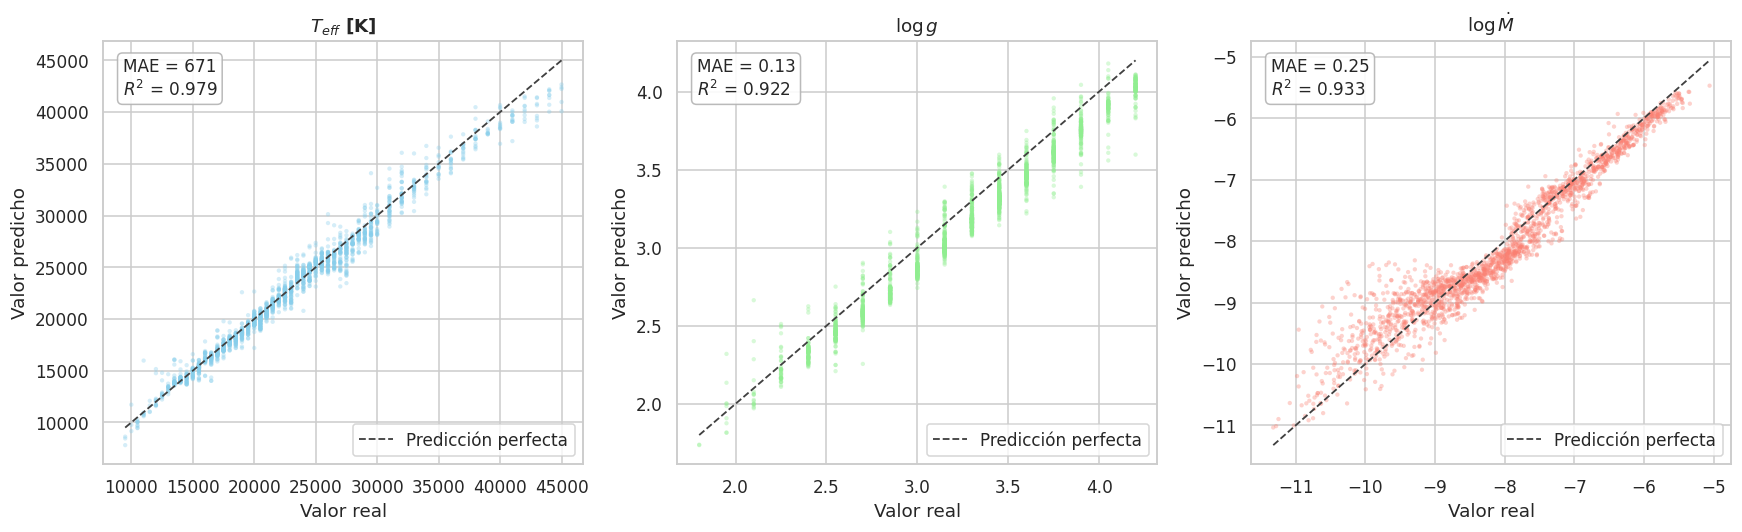

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for k, ax in enumerate(axes):
    ax.scatter(b[:, k], a[:, k], s=8, alpha=0.35, color=COLORES[k], edgecolor="none")
    lim = [b[:, k].min(), b[:, k].max()]
    ax.plot(lim, lim, "--", color="0.25", lw=1.2, label="Predicción perfecta")
    ax.text(0.04, 0.96, f"MAE = {metricas.iloc[k, 0]:.3g}\n$R^2$ = {metricas.iloc[k, 1]:.3f}",
            transform=ax.transAxes, va="top", fontsize=11,
            bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9))
    ax.set(title=NOMBRES[k], xlabel="Valor real", ylabel="Valor predicho")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 8.2 Comparación de distribuciones

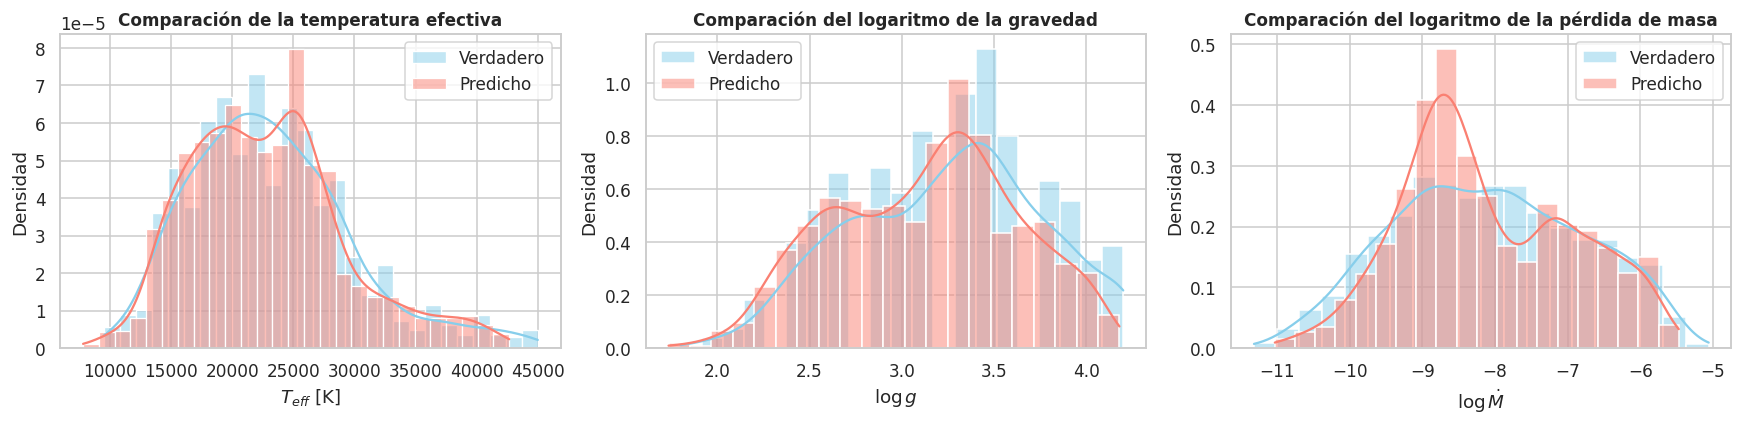

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
titulos = ["Comparación de la temperatura efectiva", "Comparación del logaritmo de la gravedad",
           "Comparación del logaritmo de la pérdida de masa"]
for k, ax in enumerate(axes):
    sns.histplot(b[:, k], kde=True, color="skyblue", label="Verdadero", stat="density", ax=ax)
    sns.histplot(a[:, k], kde=True, color="salmon", label="Predicho", stat="density", ax=ax)
    ax.set(title=titulos[k], xlabel=NOMBRES[k], ylabel="Densidad")
    ax.title.set_fontsize(11)
    ax.legend()
plt.tight_layout()
plt.show()

**Cómo leer los gráficos.** En el gráfico de valor real versus valor predicho, $T_\mathrm{eff}$ y $\log g$ toman pocos valores distintos en la grilla (ver la tabla de la sección 4), por lo que en esos paneles los puntos se agrupan en columnas verticales; el ancho vertical de cada columna es la dispersión de las predicciones para un mismo valor real. Los histogramas comparan la distribución completa: si el modelo tiende hacia el promedio, el histograma predicho queda más angosto que el verdadero.

<a id="sec-9"></a>

---
## 9. Validación en datos observados

* Los datos observados vienen con **8 líneas** por estrella y **200 puntos** de flujo por línea.
* Las líneas en orden son: Si IV 4089, H-gamma, He I 4387, He I 4471, Si III 4552, H-beta, H-alpha y He I 6678.
* Hay que sacar solo la línea **H-alpha** (índice 6) para evaluar, ya que nuestros datos de entrenamiento solo contienen H-alpha.

In [42]:
LINEAS = ["Si IV 4089", "H-gamma", "He I 4387", "He I 4471", "Si III 4552", "H-beta", "H-alpha", "He I 6678"]
print("data_observed:", data_observed.shape, "  (estrellas, líneas, puntos de flujo)")

data_observed: (76, 8, 200)   (estrellas, líneas, puntos de flujo)


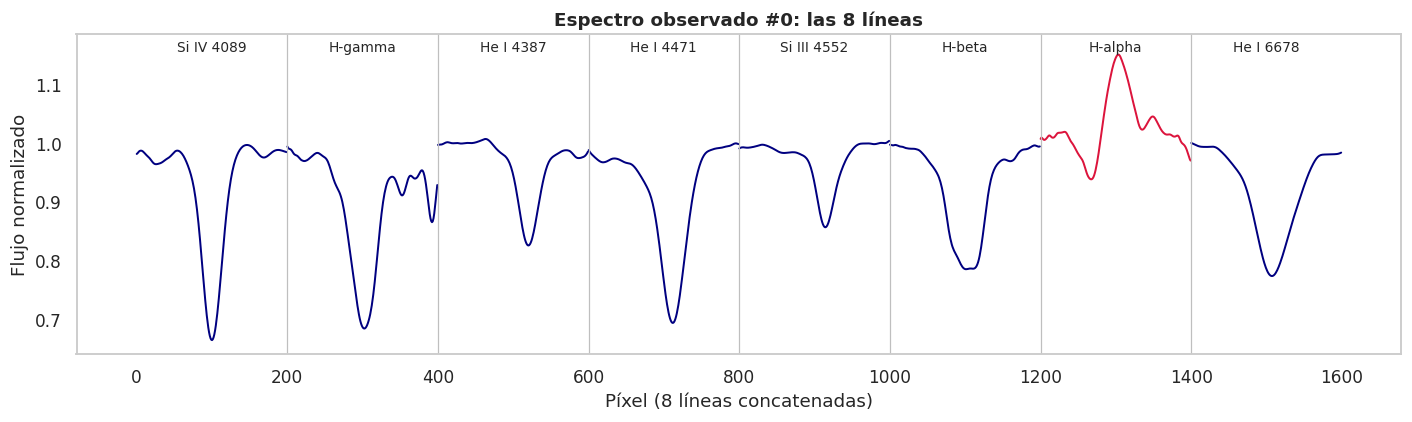

In [43]:
estrella = 0
plt.figure(figsize=(13, 4))
for k, linea in enumerate(LINEAS):
    x = np.arange(200) + 200 * k
    plt.plot(x, data_observed[estrella, k, :], lw=1.3, color="crimson" if linea == "H-alpha" else "navy")
    plt.text(x.mean(), data_observed[estrella].max() * 1.005, linea, ha="center", fontsize=9)
    if k > 0:
        plt.axvline(200 * k, color="0.75", lw=0.8)
plt.xlabel("Píxel (8 líneas concatenadas)")
plt.ylabel("Flujo normalizado")
plt.title(f"Espectro observado #{estrella}: las 8 líneas")
plt.ylim(top=data_observed[estrella].max() * 1.03)
plt.grid(False)
plt.tight_layout()
plt.show()

### 9.1 Línea H-alpha observada

Si existe la versión **preprocesada** de H-alpha (`X_observed_processed.npy`), se usa esa. Si no, se usa la línea H-alpha sin procesar extraída de `X_observed.npy`.

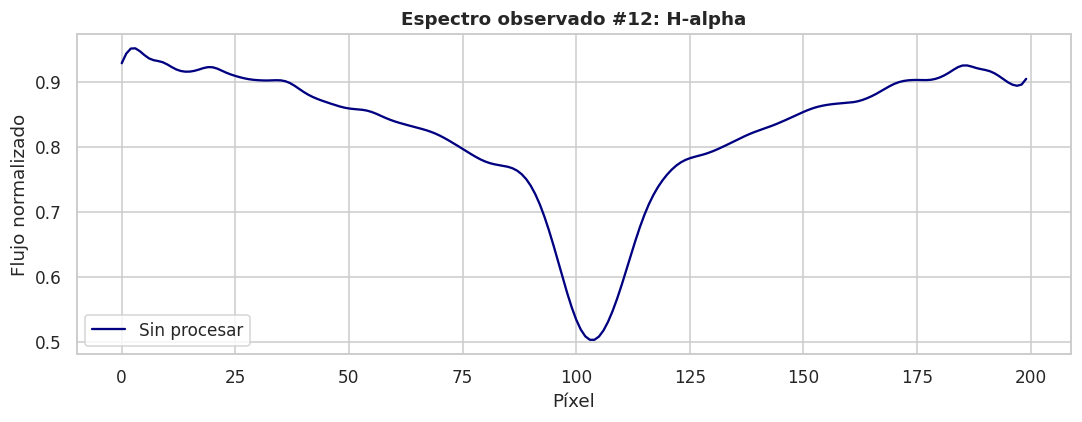

In [44]:
halpha_obs = data_observed_p if data_observed_p is not None else data_observed[:, 6, :]

estrella = 12
plt.figure(figsize=(10, 4))
plt.plot(range(200), data_observed[estrella, 6, :], color="navy", lw=1.5, label="Sin procesar")
if data_observed_p is not None:
    plt.plot(range(200), data_observed_p[estrella, :], color="crimson", lw=1.5, label="Preprocesada")
plt.xlabel("Píxel")
plt.ylabel("Flujo normalizado")
plt.title(f"Espectro observado #{estrella}: H-alpha")
plt.legend()
plt.tight_layout()
plt.show()

### 9.2 Predicción para una estrella

In [45]:
obs_x_reshaped = halpha_obs[estrella, :].reshape((1, time_steps, input_dimension))
pred_obs = model_conv1D.predict(obs_x_reshaped, verbose=0)
pred_obs_inv = scaler.inverse_transform(pred_obs)
pd.Series(pred_obs_inv.ravel(), index=["Teff [K]", "log g", "log Mdot"], name=f"Estrella #{estrella}").round(2)

Teff [K]    37983.910156
log g           4.580000
log Mdot      -10.000000
Name: Estrella #12, dtype: float32

### 9.3 Predicción para las 76 estrellas

Pasamos todas las estrellas a la red de una vez y guardamos las predicciones en un `DataFrame`.

In [46]:
obs_reshaped = halpha_obs.reshape((halpha_obs.shape[0], time_steps, input_dimension))
predicciones = scaler.inverse_transform(model_conv1D.predict(obs_reshaped, verbose=0))

df_predicciones = pd.DataFrame(predicciones, columns=["Teff", "Logg", "PerdMasa"])
df_predicciones.index.name = "ID_espectro"
df_predicciones.round({"Teff": 0, "Logg": 2, "PerdMasa": 2})

,Teff,Logg,PerdMasa
ID_espectro,,,
0,34170.0,3.86,-6.86
1,36003.0,3.72,-6.27
2,36416.0,3.76,-6.21
3,34949.0,4.38,-8.23
4,37260.0,4.04,-8.78
...,...,...,...
71,28335.0,5.08,-10.22
72,29474.0,5.35,-11.37
73,45101.0,3.25,-6.94


### 9.4 Cobertura del dominio de entrenamiento

Comparamos la distribución de las predicciones para las estrellas observadas con la distribución de los parámetros del conjunto de entrenamiento. Una predicción fuera del rango de la grilla es una señal de alerta: el modelo está **extrapolando**.

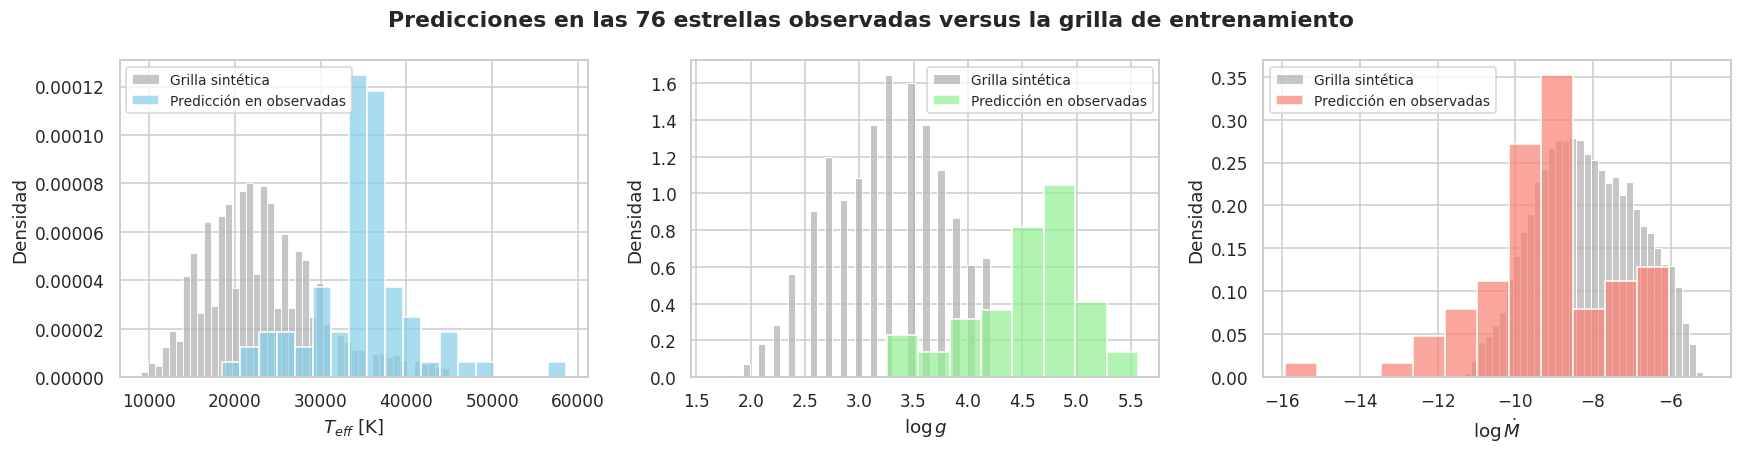

Estrellas con al menos un parámetro fuera del rango de la grilla: 59 de 76


In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for k, ax in enumerate(axes):
    sns.histplot(y_new[:, k], color="0.7", stat="density", label="Grilla sintética", ax=ax)
    sns.histplot(predicciones[:, k], color=COLORES[k], stat="density", label="Predicción en observadas",
                 ax=ax, alpha=0.7)
    ax.set(xlabel=NOMBRES[k], ylabel="Densidad")
    ax.legend(fontsize=9)
plt.suptitle("Predicciones en las 76 estrellas observadas versus la grilla de entrenamiento", fontweight="bold")
plt.tight_layout()
plt.show()

fuera = ((predicciones < y_new.min(axis=0)) | (predicciones > y_new.max(axis=0))).any(axis=1)
print(f"Estrellas con al menos un parámetro fuera del rango de la grilla: {fuera.sum()} de {len(fuera)}")

<a id="sec-10"></a>

---
## 10. Preguntas abiertas

1. `EarlyStopping` vigila la pérdida de **training** (`monitor='loss'`). ¿Qué cambia si vigila `val_loss` y se agrega `restore_best_weights=True`?
2. Agregue capas `BatchNormalization` o `Dropout` y compare las curvas de aprendizaje.
3. $\log g$ toma solo 18 valores en la grilla. ¿Conviene tratarlo como **clasificación** en vez de regresión?
4. Los espectros sintéticos no tienen ruido y los observados sí. ¿Cómo podría agregar ruido a los sintéticos durante el entrenamiento para mejorar la generalización?

**Respuestas**

1.
2.
3.
4.

Trabajando con clasificador para $\log g$

In [58]:
#y_logg_train = y_new[:, 1]
print(np.shape(y_train[:,1,:]), np.shape(y_val[:,1, :]))
def buildClasificadorLogG():
    n_timesteps = X_train_reshaped.shape[1]  # 200
    n_features = X_train_reshaped.shape[2]   # 1
    model = keras.Sequential(name="logg_Conv1D")
    model.add(keras.layers.Input(shape=(n_timesteps, n_features)))
    
    model.add(keras.layers.Conv1D(64, 5))
    model.add(keras.layers.Conv1D(32, 5))
    model.add(keras.layers.Conv1D(16, 5))

    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(18, activation="softmax", name="Dense_4"))

    model.compile(loss='mae', optimizer= "adam", metrics=['f1_score'])
    model.summary()
    return model

clasificador = buildClasificadorLogG()
history = clasificador.fit(X_train_reshaped, 
                          y_train[:,1], 
                          epochs=50, 
                          validation_data=(X_val_reshaped, y_val[:,1]),
                          batch_size=20,
                          callbacks=[keras.callbacks.EarlyStopping(patience=7, restore_best_weights=False),
                                     keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=7)])


clasificador.save("clasificador.keras")
mejoresParametrosC = clasificador.get_best_hyperparameters()

IndexError: too many indices for array: array is 2-dimensional, but 3 were indexed

In [ ]:
obs_reshaped = halpha_obs.reshape((halpha_obs.shape[0], time_steps, input_dimension))[:,1]
predicciones = scaler.inverse_transform(mejorClasificador.predict(obs_reshaped, verbose=0))

df_predicciones = pd.DataFrame(predicciones, columns=["Logg"])
df_predicciones.index.name = "ID_espectro"
df_predicciones.round({"Logg": 2})

fig, axes = plt.subplots(1, 1, figsize=(16, 4.2))
sns.histplot(y_new[:, 1], color="0.7", stat="density", label="Grilla sintética", ax=ax)
sns.histplot(predicciones[:, 0], color=COLORES[1], stat="density", label="Predicción en observadas",
                 ax=ax, alpha=0.7)
ax.set(xlabel=NOMBRES[1], ylabel="Densidad")
ax.legend(fontsize=9)
plt.suptitle("Predicciones en las 76 estrellas observadas versus la grilla de entrenamiento", fontweight="bold")
plt.tight_layout()
plt.show()

fuera = ((predicciones < y_new.min(axis=0)) | (predicciones > y_new.max(axis=0))).any(axis=1)
print(f"Estrellas con al menos un parámetro fuera del rango de la grilla: {fuera.sum()} de {len(fuera)}")

<a id="sec-11"></a>

---
## 11. Resumen

1. **Etapas.** Un proyecto de machine learning recorre la obtención de datos, el análisis exploratorio, la partición, el diseño del modelo y la validación, primero en datos sintéticos y después en datos observados.
2. **Escalamiento.** Las salidas viven en escalas muy distintas; `MinMaxScaler` las lleva a $[0, 1]$ para que ninguna domine la pérdida, y `inverse_transform` las devuelve a unidades físicas.
3. **CNN 1D.** Los filtros convolucionales comparten pesos a lo largo del espectro y detectan patrones locales del perfil de línea.
4. **Curvas de aprendizaje.** Comparar la pérdida de training y de validation por época permite detectar sobreajuste.
5. **Dominio de entrenamiento.** Una predicción fuera del rango de la grilla indica que el modelo extrapola.

---

### Referencias

- Araya, I., Curé, M., Machuca, N., et al. (2025). *ISOSCELES project: A grid-based quantitative spectroscopic analysis of massive stars.* [arXiv:2511.03184](https://arxiv.org/abs/2511.03184)
- LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). *Gradient-based learning applied to document recognition.* Proceedings of the IEEE, 86(11), 2278–2324. [doi:10.1109/5.726791](https://doi.org/10.1109/5.726791)
- Klambauer, G., Unterthiner, T., Mayr, A., & Hochreiter, S. (2017). *Self-normalizing neural networks.* NeurIPS 30. [arXiv:1706.02515](https://arxiv.org/abs/1706.02515)
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2.ª ed.). Springer. [doi:10.1007/978-0-387-84858-7](https://doi.org/10.1007/978-0-387-84858-7)